In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
data_path="/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/2026 ASA DataQuest/WPP2024_Demographic_Indicators_Medium_csv.gz"
df=pd.read_csv(data_path,compression="gzip",
                 encoding="utf-8-sig",
                 low_memory=False)
# df=pd.DataFrame(data)
df.columns

# data["TPopulation1Jan"]


Index(['SortOrder', 'LocID', 'Notes', 'ISO3_code', 'ISO2_code', 'SDMX_code',
       'LocTypeID', 'LocTypeName', 'ParentID', 'Location', 'VarID', 'Variant',
       'Time', 'TPopulation1Jan', 'TPopulation1July', 'TPopulationMale1July',
       'TPopulationFemale1July', 'PopDensity', 'PopSexRatio', 'MedianAgePop',
       'NatChange', 'NatChangeRT', 'PopChange', 'PopGrowthRate',
       'DoublingTime', 'Births', 'Births1519', 'CBR', 'TFR', 'NRR', 'MAC',
       'SRB', 'Deaths', 'DeathsMale', 'DeathsFemale', 'CDR', 'LEx', 'LExMale',
       'LExFemale', 'LE15', 'LE15Male', 'LE15Female', 'LE65', 'LE65Male',
       'LE65Female', 'LE80', 'LE80Male', 'LE80Female', 'InfantDeaths', 'IMR',
       'LBsurvivingAge1', 'Under5Deaths', 'Q5', 'Q0040', 'Q0040Male',
       'Q0040Female', 'Q0060', 'Q0060Male', 'Q0060Female', 'Q1550',
       'Q1550Male', 'Q1550Female', 'Q1560', 'Q1560Male', 'Q1560Female',
       'NetMigrations', 'CNMR'],
      dtype='object')

In [22]:
data_path="/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/2026 ASA DataQuest/WPP2024_Demographic_Indicators_Medium_csv.gz"
data=pd.read_csv(data_path,compression="gzip",
                 encoding="utf-8-sig",
                 low_memory=False)
# df=pd.DataFrame(data)
data.columns

# data["TPopulation1Jan"]


Index(['SortOrder', 'LocID', 'Notes', 'ISO3_code', 'ISO2_code', 'SDMX_code',
       'LocTypeID', 'LocTypeName', 'ParentID', 'Location', 'VarID', 'Variant',
       'Time', 'TPopulation1Jan', 'TPopulation1July', 'TPopulationMale1July',
       'TPopulationFemale1July', 'PopDensity', 'PopSexRatio', 'MedianAgePop',
       'NatChange', 'NatChangeRT', 'PopChange', 'PopGrowthRate',
       'DoublingTime', 'Births', 'Births1519', 'CBR', 'TFR', 'NRR', 'MAC',
       'SRB', 'Deaths', 'DeathsMale', 'DeathsFemale', 'CDR', 'LEx', 'LExMale',
       'LExFemale', 'LE15', 'LE15Male', 'LE15Female', 'LE65', 'LE65Male',
       'LE65Female', 'LE80', 'LE80Male', 'LE80Female', 'InfantDeaths', 'IMR',
       'LBsurvivingAge1', 'Under5Deaths', 'Q5', 'Q0040', 'Q0040Male',
       'Q0040Female', 'Q0060', 'Q0060Male', 'Q0060Female', 'Q1550',
       'Q1550Male', 'Q1550Female', 'Q1560', 'Q1560Male', 'Q1560Female',
       'NetMigrations', 'CNMR'],
      dtype='object')

Variant
Medium    84360
Name: count, dtype: int64


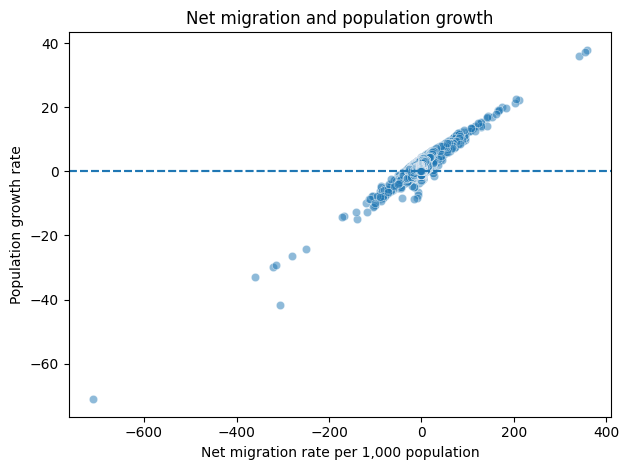

/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


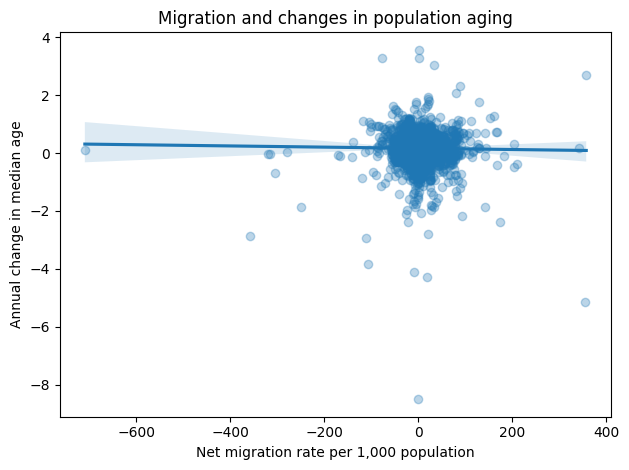

                 CNMR  PopGrowthRate  MedianAgePop  ChangeMedianAge   TFR  \
CNMR             1.00           0.68          0.07            -0.01 -0.05   
PopGrowthRate    0.68           1.00         -0.64            -0.16  0.60   
MedianAgePop     0.07          -0.64          1.00             0.13 -0.79   
ChangeMedianAge -0.01          -0.16          0.13             1.00 -0.41   
TFR             -0.05           0.60         -0.79            -0.41  1.00   
NatChangeRT     -0.04           0.70         -0.95            -0.20  0.87   

                 NatChangeRT  
CNMR                   -0.04  
PopGrowthRate           0.70  
MedianAgePop           -0.95  
ChangeMedianAge        -0.20  
TFR                     0.87  
NatChangeRT             1.00  


In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# Now call axhline on plt, not matplotlib_inline

# Keep one consistent scenario for the analysis.
print(data["Variant"].value_counts(dropna=False))

# Use the baseline/medium variant only if that is
# the appropriate label in your dataset.
# Check the actual labels before filtering.
data = data.copy()

# Convert key columns to numeric.
cols = [
    "Time", "CNMR", "NetMigrations", "MedianAgePop",
    "PopGrowthRate", "NatChangeRT", "TFR"
]

for col in cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Retain one observation per location and year.
data = data.dropna(
    subset=["ISO3_code", "Time", "MedianAgePop", "CNMR"]
)

data = data.sort_values(["ISO3_code", "Time"])

# Calculate annual changes in median age.
data["ChangeMedianAge"] = (
    data.groupby("ISO3_code")["MedianAgePop"].diff()
)

# Explore migration and population growth.
sns.scatterplot(
    data=data,
    x="CNMR",
    y="PopGrowthRate",
    alpha=0.5
)

plt.axhline(0, linestyle="--")
plt.axhline(0, linestyle="--")
plt.xlabel("Net migration rate per 1,000 population")
plt.ylabel("Population growth rate")
plt.title("Net migration and population growth")
plt.tight_layout()
plt.show()

# Explore migration and annual changes in median age.
sns.regplot(
    data=data,
    x="CNMR",
    y="ChangeMedianAge",
    scatter_kws={"alpha": 0.3}
)

plt.xlabel("Net migration rate per 1,000 population")
plt.ylabel("Annual change in median age")
plt.title("Migration and changes in population aging")
plt.tight_layout()
plt.show()

# Check the correlations among the key variables.
print(
    data[[
        "CNMR", "PopGrowthRate", "MedianAgePop",
        "ChangeMedianAge", "TFR", "NatChangeRT"
    ]].corr().round(2)
)


In [24]:

import pandas as pd
import numpy as np

# Load the demographic data
demo = data.copy()

# Convert numeric fields
numeric_cols = [
    "Time",
    "TPopulation1July",
    "PopGrowthRate",
    "NetMigrations",
    "CNMR",
    "PopDensity",
    "NatChangeRT",
    "MedianAgePop",
    "TFR",
]

for col in numeric_cols:
    demo[col] = pd.to_numeric(demo[col], errors="coerce")

# Inspect data coverage and population variants
print(demo["Variant"].value_counts(dropna=False))
print(demo["LocTypeName"].value_counts(dropna=False))
print(demo["Time"].min(), demo["Time"].max())

# Keep only country-level rows after checking LocTypeName.
# Adapt this filter to the actual labels in your dataset.
demo = demo.dropna(subset=["ISO3_code", "Time"])

# Select one consistent historical series.
# Inspect Variant labels before applying a filter.
# Do not mix projections with historical observations.

demo = demo.sort_values(["ISO3_code", "Time"])

# Calculate annual change in population size as a check.
demo["population_change_pct"] = (
    demo.groupby(["ISO3_code", "Variant"])["TPopulation1July"]
        .pct_change() * 100
)

# Suppose rent contains:
# ISO3_code, year, rent_index
rent = datas.copy()
rent["year"] = pd.to_numeric(rent["year"], errors="coerce")
rent["rent_index"] = pd.to_numeric(
    rent["rent_index"], errors="coerce"
)

rent = rent.sort_values(["ISO3_code", "year"])

# Year-over-year rent-index growth
rent["rent_growth_yoy"] = (
    rent.groupby("ISO3_code")["rent_index"]
        .pct_change() * 100
)

# Merge on country and year, after verifying compatible
# definitions, time periods, and units.
demo = demo.rename(columns={"Time": "year"})

panel = demo.merge(
    rent[["ISO3_code", "year", "rent_index", "rent_growth_yoy"]],
    on=["ISO3_code", "year"],
    how="inner",
    validate="many_to_one"
)

print("Countries:", panel["ISO3_code"].nunique())
print("Observations:", len(panel))
print("Year range:", panel["year"].min(), panel["year"].max())
print(panel[["rent_growth_yoy", "PopGrowthRate", "CNMR"]].isna().mean())


Variant
Medium    35787
Name: count, dtype: int64
LocTypeName
Country/Area    35787
Name: count, dtype: int64
1950 2100


NameError: name 'datas' is not defined

In [25]:

# 1. Which geographical units are included?
print(df["LocTypeName"].value_counts(dropna=False))

# 2. Which locations are included?
print(df[["Location", "ISO3_code"]]
      .drop_duplicates()
      .head(30))

# 3. What time period does the data cover?
print(df["Time"].min(), df["Time"].max())

# 4. Are there multiple population scenarios?
print(df["Variant"].value_counts(dropna=False))

# 5. How complete are the main demographic variables?
cols = [
    "PopGrowthRate",
    "NetMigrations",
    "CNMR",
    "PopDensity",
    "NatChangeRT",
    "MedianAgePop"
]

print(df[cols].isna().mean().sort_values())


LocTypeName
Country/Area         36024
NaN                  35568
Ad Hoc groups         3496
Subregion             3192
SDG region            1368
Income group          1368
Development group     1064
Special other         1064
Geographic region     1064
World                  152
Name: count, dtype: int64
                                               Location ISO3_code
0                     ADB region: Central and West Asia       NaN
152                               ADB region: Developed       NaN
304                               ADB region: East Asia       NaN
456                              ADB region: South Asia       NaN
608                          ADB region: Southeast Asia       NaN
760                             ADB region: The Pacific       NaN
912                                               AUKUS       NaN
1064                                      African Group       NaN
1216                                      African Union       NaN
1368                      Africa

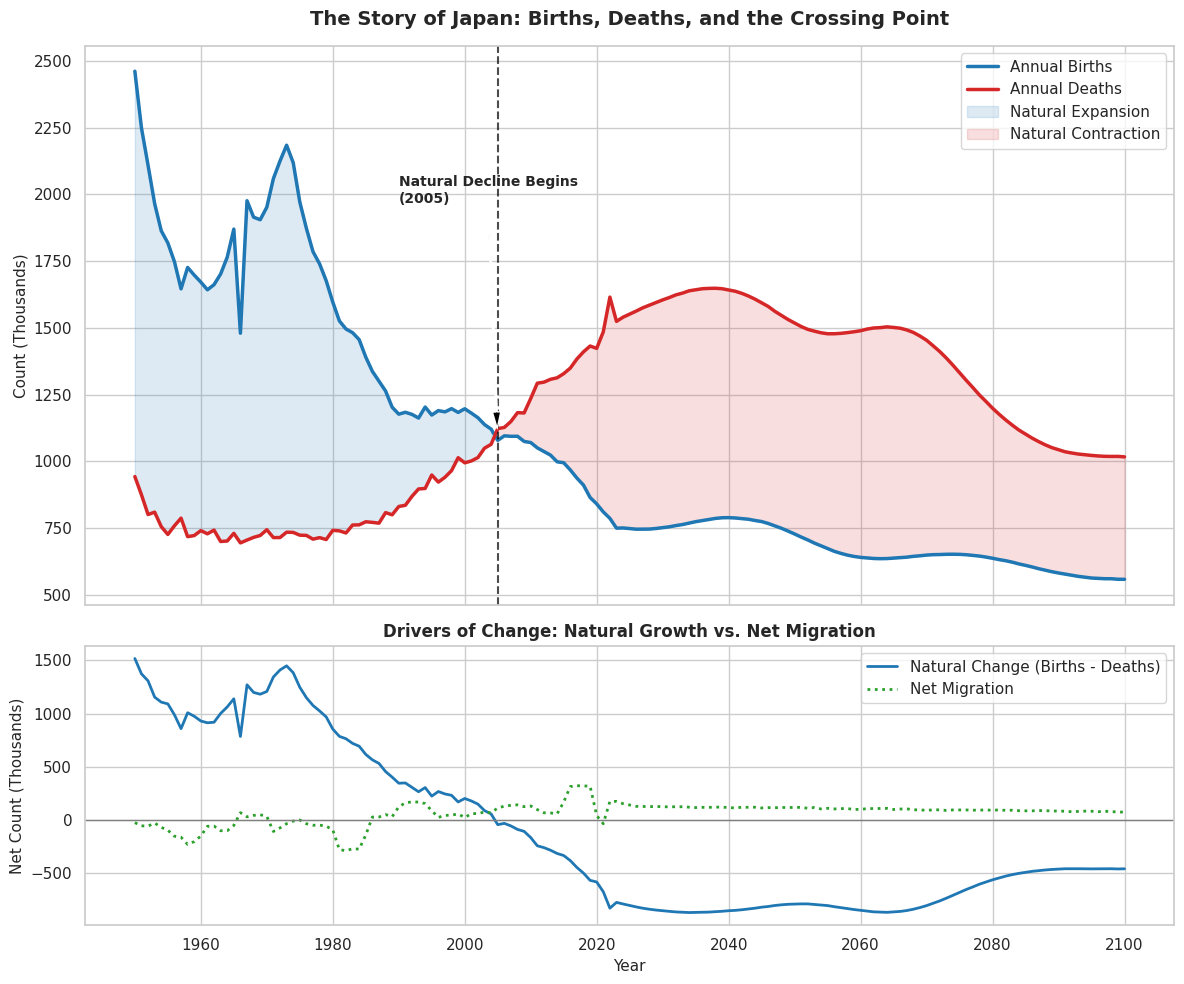

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# 1. Load Data & Filter Region (Replace 'Location' with your target region)
# df = pd.read_csv("UN_WPP_Data.csv")

# Filter for baseline scenario and target location
target_region = "Japan"  # Example region experiencing natural decline
df_story = df[
    (df["Location"] == target_region) & (df["Variant"] == "Medium")
].sort_values("Time")

# 2. Extract Data Metrics
years = df_story["Time"]
births = df_story["Births"]
deaths = df_story["Deaths"]
nat_change = df_story["NatChange"]
net_migration = df_story["NetMigrations"]
total_pop = df_story["TPopulation1July"] / 1000  # Millions

# 3. Create Narrative Visualization
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

# Plot 1: The Crossing Point (Births vs Deaths)
ax1.plot(years, births, label="Annual Births", color="#1f77b4", linewidth=2.5)
ax1.plot(years, deaths, label="Annual Deaths", color="#d62728", linewidth=2.5)

# Shade Natural Increase vs Natural Decrease
ax1.fill_between(
    years,
    births,
    deaths,
    where=(births >= deaths),
    color="#1f77b4",
    alpha=0.15,
    label="Natural Expansion",
)
ax1.fill_between(
    years,
    births,
    deaths,
    where=(births < deaths),
    color="#d62728",
    alpha=0.15,
    label="Natural Contraction",
)

# Identify Crossing Year
crossing_df = df_story[df_story["NatChange"] <= 0]
if not crossing_df.empty:
    crossing_year = crossing_df.iloc[0]["Time"]
    ax1.axvline(
        x=crossing_year,
        color="black",
        linestyle="--",
        alpha=0.7,
        linewidth=1.5,
    )
    ax1.annotate(
        f"Natural Decline Begins\n({crossing_year})",
        xy=(crossing_year, births[years == crossing_year].values[0]),
        xytext=(crossing_year - 15, births.max() * 0.8),
        arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
        fontsize=10,
        fontweight="bold",
    )

ax1.set_title(
    f"The Story of {target_region}: Births, Deaths, and the Crossing Point",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax1.set_ylabel("Count (Thousands)", fontsize=11)
ax1.legend(loc="upper right", frameon=True)

# Plot 2: Net Migration vs Natural Change Impact on Total Population
ax2.plot(
    years,
    nat_change,
    label="Natural Change (Births - Deaths)",
    color="#d62728" if nat_change.iloc[-1] < 0 else "#1f77b4",
    linewidth=2,
)
ax2.plot(
    years,
    net_migration,
    label="Net Migration",
    color="#2ca02c",
    linewidth=2,
    linestyle=":",
)
ax2.axhline(0, color="gray", linewidth=1, linestyle="-")

ax2.set_title(
    "Drivers of Change: Natural Growth vs. Net Migration",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Year", fontsize=11)
ax2.set_ylabel("Net Count (Thousands)", fontsize=11)
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

=== Demographic Archetype Summary (2101) ===

Location: Türkiye
  - Archetype: Natural Expansion (High Birth Rate)
  - TFR: nan | Natural Growth Rate: nan/1k | Net Migration Rate: nan/1k
  - Total Population Growth Rate: nan%

Location: United Arab Emirates
  - Archetype: Natural Expansion (High Birth Rate)
  - TFR: nan | Natural Growth Rate: nan/1k | Net Migration Rate: nan/1k
  - Total Population Growth Rate: nan%

Location: Egypt
  - Archetype: Natural Expansion (High Birth Rate)
  - TFR: nan | Natural Growth Rate: nan/1k | Net Migration Rate: nan/1k
  - Total Population Growth Rate: nan%

Location: Saudi Arabia
  - Archetype: Natural Expansion (High Birth Rate)
  - TFR: nan | Natural Growth Rate: nan/1k | Net Migration Rate: nan/1k
  - Total Population Growth Rate: nan%


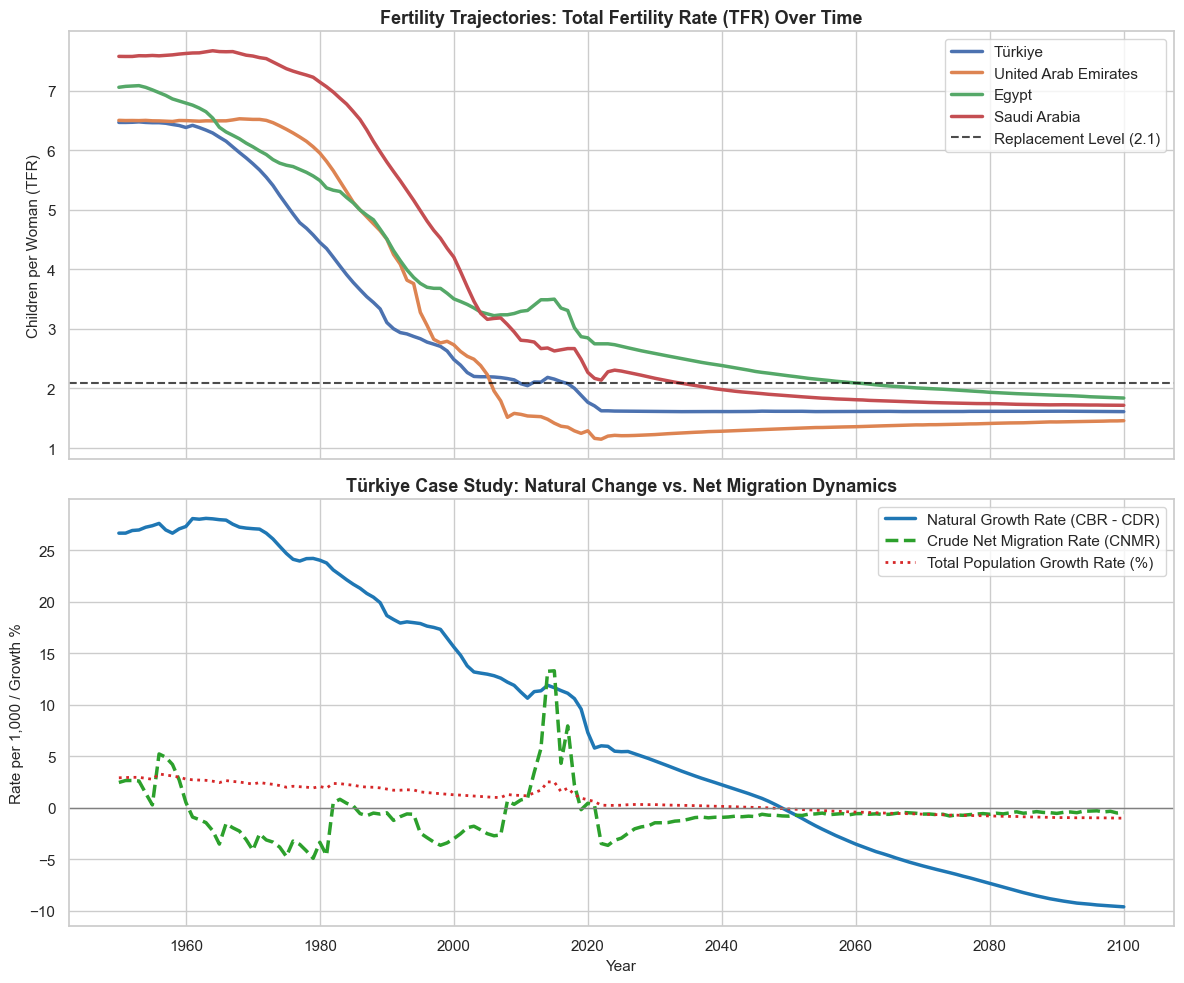

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set clean visualization defaults
sns.set_theme(style="whitegrid")


def analyze_demographic_drivers(
    df: pd.DataFrame, countries: list, variant: str = "Medium"
):
    """Decomposes population growth into Natural Change Rate and Net Migration Rate,

    and compares Total Fertility Rate across target Middle Eastern countries.
    """
    # Filter dataset for requested locations and baseline variant
    sub_df = df[
        (df["Location"].isin(countries)) & (df["Variant"] == variant)
    ].copy()

    # Calculate Natural Change Rate if not already explicit (CBR - CDR)
    if "NatChangeRT" not in sub_df.columns:
        sub_df["NatChangeRT"] = sub_df["CBR"] - sub_df["CDR"]

    # 1. Summary Archetype Profiler
    latest_year = sub_df["Time"].max()
    latest_data = sub_df[sub_df["Time"] == latest_year].set_index("Location")

    print(f"=== Demographic Archetype Summary ({latest_year}) ===")
    for country in countries:
        if country in latest_data.index:
            row = latest_data.loc[country]
            tfr = row["TFR"]
            nat_rate = row["NatChangeRT"]
            cnmr = row["CNMR"]
            growth = row["PopGrowthRate"]

            # Archetype classification logic
            if cnmr > nat_rate and cnmr > 5:
                archetype = "Migration-Driven Growth (GCC Model)"
            elif tfr < 2.1 and nat_rate < 8:
                archetype = "Advanced Demographic Transition (Aging/Slowing)"
            else:
                archetype = "Natural Expansion (High Birth Rate)"

            print(f"\nLocation: {country}")
            print(f"  - Archetype: {archetype}")
            print(
                f"  - TFR: {tfr:.2f} | Natural Growth Rate: {nat_rate:.1f}/1k | Net Migration Rate: {cnmr:.1f}/1k"
            )
            print(f"  - Total Population Growth Rate: {growth:.2f}%")

    # 2. Time-Series Trajectory Visualization
    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    # Plot Total Fertility Rate (TFR) against Replacement Level (2.1)
    for country in countries:
        c_data = sub_df[sub_df["Location"] == country].sort_values("Time")
        axes[0].plot(
            c_data["Time"], c_data["TFR"], label=country, linewidth=2.5
        )

    axes[0].axhline(
        2.1,
        color="black",
        linestyle="--",
        alpha=0.7,
        label="Replacement Level (2.1)",
    )
    axes[0].set_title(
        "Fertility Trajectories: Total Fertility Rate (TFR) Over Time",
        fontsize=13,
        fontweight="bold",
    )
    axes[0].set_ylabel("Children per Woman (TFR)", fontsize=11)
    axes[0].legend(loc="upper right")

    # Plot Decomposed Growth Drivers for Turkey as a Case Study
    turkey_data = sub_df[sub_df["Location"] == "Türkiye"].sort_values("Time")
    if not turkey_data.empty:
        axes[1].plot(
            turkey_data["Time"],
            turkey_data["NatChangeRT"],
            label="Natural Growth Rate (CBR - CDR)",
            color="#1f77b4",
            linewidth=2.5,
        )
        axes[1].plot(
            turkey_data["Time"],
            turkey_data["CNMR"],
            label="Crude Net Migration Rate (CNMR)",
            color="#2ca02c",
            linewidth=2.5,
            linestyle="--",
        )
        axes[1].plot(
            turkey_data["Time"],
            turkey_data["PopGrowthRate"],
            label="Total Population Growth Rate (%)",
            color="#d62728",
            linewidth=2,
            linestyle=":",
        )
        axes[1].axhline(0, color="gray", linewidth=1)
        axes[1].set_title(
            "Türkiye Case Study: Natural Change vs. Net Migration Dynamics",
            fontsize=13,
            fontweight="bold",
        )
        axes[1].set_ylabel("Rate per 1,000 / Growth %", fontsize=11)
        axes[1].set_xlabel("Year", fontsize=11)
        axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.show()

# Example invocation (Replace 'df' with your loaded UN WPP DataFrame):
analyze_demographic_drivers(df, countries=['Türkiye', 'United Arab Emirates', 'Egypt', 'Saudi Arabia'])